In [ ]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

In [10]:
#importing the part of the data I want from 2025A
fieldcube = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_filtered_fields.fits')
fields = fieldcube[0:2000]

In [ ]:
ADC = AdcFitter(wavelength=764E-9,bandwidth=120E-9)

[-3.16566888 -1.73293837]


In [ ]:
#function to show the image i fit so i can compare it to the image i actually took
def visualize_fit(image):
    speckle_angles = np.zeros(4)
    sig_x = [0.8,3.5,0.8,3.5]
    sig_y = [3.5,0.8,3.5,0.8]
    fit_image = image - image

    for i in range(4):
        img = ADC.find_speckle(ADC.psf,i)
        ADC.current_speckle = i
        ADC.set_measurement(img)

        sigma_x = sig_x[i]
        sigma_y = sig_y[i]
        #orientation = np.radians(28)

        orientation = ADC.estimate_angle()
        if ADC.current_speckle == 0 or ADC.current_speckle ==2:
            orientation = np.pi/2 - orientation
        elif ADC.current_speckle == 1 or ADC.current_speckle == 3:
            orientation = -orientation

        #params common to all four
        amplitude = ADC.data.max()
        centroid = ADC.estimate_centroid()
        mu_x = centroid[0]
        mu_y = centroid[1]
        background = 0

        theta_est = np.array([amplitude, mu_x, mu_y, sigma_x, sigma_y, orientation, background])
        fit = ADC.fit(theta_est) 
        theta = fit.x
        speckle_angles[i] = np.degrees(fit.x[5])
        fit_image = fit_image + ADC.satellite_spot(*theta)(image.grid)

    ADC.current_speckle = None
    speckle_angles = np.array(speckle_angles).T

    return fit_image

In [67]:
#now to sync up with the angle measurements
#angles were measured once every 16 frames
avg_imgs = []

for i in range(0,len(fields)-16,16):
    interval = [i,i+16]
    avg_img = sum(fields[interval[0]:interval[1]])/16
    avg_imgs.append(avg_img)

In [69]:
interval = [16 - 16,16]
avg_img = sum(fields[interval[0]:interval[1]])/16

sums = sum(fields[0:16])/16
#imshow_field(avg_imgs[8])
#print(len(avg_imgs))

print(len(fields)/16)
print(len(avg_imgs))
print(avg_imgs[123])

125.0
124
[0. 0. 0. ... 0. 0. 0.]


In [ ]:
#now that we've stacked the images, we can process them
speckle_angles = []
pointings = []

for i, field in enumerate(avg_imgs):
    ADC.set_psf(field)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)

pointings = np.array(pointings)
speckle_angles = np.array(speckle_angles)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123


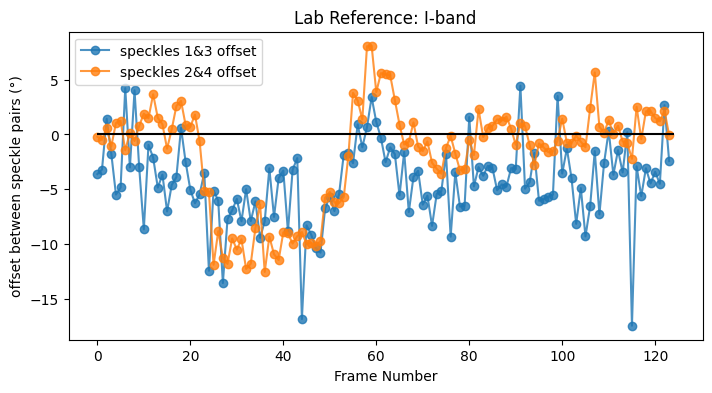

In [71]:
plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
plt.plot(pointings[:,0],'-o',label='speckles 1&3 offset',alpha=0.8)
plt.plot(pointings[:,1],'-o',label='speckles 2&4 offset',alpha=0.8)
plt.hlines(0,0,len(pointings),'black')
plt.xlabel('Frame Number')
plt.ylabel('offset between speckle pairs (°)')
plt.title('Lab Reference: I-band')
plt.legend()

In [94]:
#now to scale the y-axis to be in mas/um
#the scaling factor for this comes from when I measured the companion FWHM
#/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/datacubes.ipynb
#we know from that data that 5° of adc shear resulted in a FWHM increase from 6->14, at 6 mas/px and bw=120nm:
fivedegrees = (14-6)*6/.12
#but when i did it this time, i only perturbed the ADCs by three degrees:
threedegrees = fivedegrees * 3/5
print(threedegrees)
pointings_scaled0 = pointings[:,0]/np.max(np.abs(pointings),axis=0)[0] * threedegrees
pointings_scaled1 = pointings[:,1]/np.max(np.abs(pointings),axis=0)[1] * threedegrees

240.0


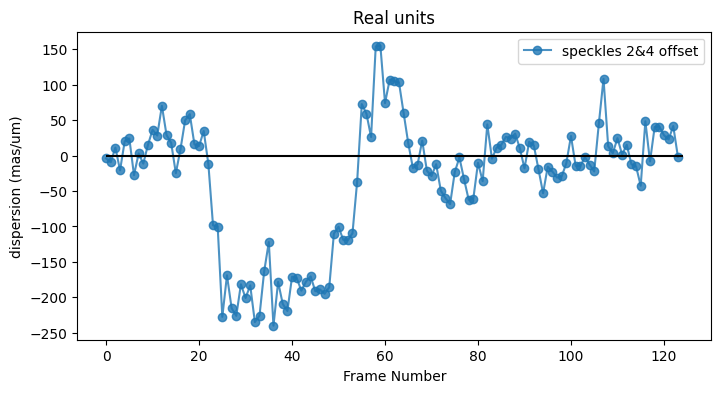

In [100]:
plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
#plt.plot(pointings_scaled0,'-o',label='speckles 1&3 offset',alpha=0.8)
plt.plot(pointings_scaled1,'-o',label='speckles 2&4 offset',alpha=0.8)
plt.hlines(0,0,len(pointings_scaled0),'black')
plt.xlabel('Frame Number')
plt.ylabel('dispersion (mas/um)')
plt.title('Real units')
plt.legend()

In [105]:
#well that's not great. let's look at the variance once the loop has "converged"
converged = pointings_scaled1[80:]
print(f'mean: {np.mean(converged)}')
print(f'standard deviation: {np.std(converged)}')


mean: 5.89390674909857
standard deviation: 29.758050825045405
